# SOLUTIONS
Try the exercise notebook first.

# Practice: eyes open vs. eyes closed, three ways

Same effect as the Ganglion demo: alpha (8–12 Hz) rises at the back of the head when eyes close. Here you'll train three kinds of model to detect it from real lab EEG, then try the simplest one on your own Ganglion recording.

**Data:** [PhysioNet EEG Motor Movement/Imagery dataset](https://physionet.org/content/eegmmidb/1.0.0/), downloaded automatically in section 1 (about 2 MB per run). For each person, run 1 is 1 minute with eyes open and run 2 is 1 minute with eyes closed, recorded with 64 electrodes at 160 Hz. We cut each minute into 2-second windows.

**The three models**
1. **Band power + LDA** on a single channel (Oz), like the Ganglion's one channel
2. **Riemannian** (covariance matrices + tangent space) on 5 back-of-head channels
3. **EEGNet**, a small deep learning model, on the same 5 channels

**How to use it:** fill each `___`, predict outputs before running, check against `practice_eyes_SOLUTIONS.ipynb` only when stuck.

Install once in your virtual environment: `pip install mne pyriemann scikit-learn matplotlib braindecode`

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mne
from mne.datasets import eegbci
from scipy.signal import welch
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import GroupKFold, cross_val_score
mne.set_log_level("WARNING")

def check(ok, good="Correct!", bad="Not quite, look at the TODO again."):
    print(good if ok else bad)

## 1. Load the data

`eegbci.load_data` downloads the EDF files (small, about 2 MB per run). `standardize` renames channels to standard names like `Oz`.

We use 10 people. **Predict:** each run is 60 s, cut into 2 s windows, two runs per person. How many windows per person?

In [2]:
SUBJECTS = list(range(1, 11))
CHANNELS = ["O1", "Oz", "O2", "PO7", "PO8"]   # back of the head
WIN = 2.0                                      # window length in seconds

X_list, y_list, groups = [], [], []
for subj in SUBJECTS:
    # TODO: which two runs are the eyes-open and eyes-closed baselines?
    files = eegbci.load_data(subj, runs=[1, 2], update_path=True)
    for label, f in enumerate(files):          # label 0 = eyes open (run 1), 1 = eyes closed (run 2)
        raw = mne.io.read_raw_edf(f, preload=True)
        eegbci.standardize(raw)
        raw.pick(CHANNELS).filter(1.0, 40.0)
        epochs = mne.make_fixed_length_epochs(raw, duration=WIN, preload=True)
        data = epochs.get_data()               # (windows, channels, samples)
        X_list.append(data)
        y_list.append(np.full(len(data), label))
        groups.append(np.full(len(data), subj))

X = np.concatenate(X_list); y = np.concatenate(y_list); groups = np.concatenate(groups)
FS = int(raw.info["sfreq"])
print("X:", X.shape, " y counts:", np.bincount(y), " sampling rate:", FS)

# TODO: how many channels did we keep?
check(X.shape[1] == 5)

/Users/siddhantgulati/Documents/TNT Ceiling Benchmark/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


X: (600, 5, 320)  y counts: [300 300]  sampling rate: 160
Correct!


## 2. Look before you model

Plot the average spectrum at Oz for eyes open vs. closed. You should see a bump at 8–12 Hz for eyes closed.

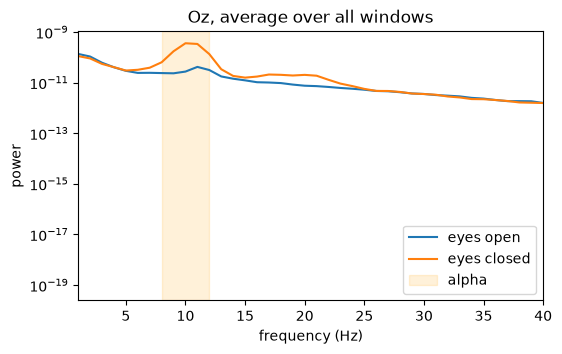

In [3]:
oz = CHANNELS.index("Oz")
freqs, psd = welch(X[:, oz, :], fs=FS, nperseg=FS)

plt.figure(figsize=(6, 3.5))
for label, name in [(0, "eyes open"), (1, "eyes closed")]:
    plt.semilogy(freqs, psd[y == label].mean(axis=0), label=name)
plt.axvspan(8, 12, alpha=0.15, color="orange", label="alpha")
plt.xlim(1, 40); plt.xlabel("frequency (Hz)"); plt.ylabel("power")
plt.legend(); plt.title("Oz, average over all windows"); plt.show()

## 3. Model 1: band power + LDA on one channel

**Feature:** relative alpha power, alpha power divided by total power (1–40 Hz). We use *relative* power because absolute power depends on the hardware and electrode contact. Relative power is what lets us later apply this model to the Ganglion.

**Evaluation:** `GroupKFold` keeps each person's windows together, so the model is always tested on **people it never saw**. Splitting windows randomly would let it train and test on the same person, which inflates accuracy.

In [4]:
def relative_alpha(X_one_channel, fs):
    # X_one_channel: (windows, samples). Returns (windows, 1).
    f, p = welch(X_one_channel, fs=fs, nperseg=fs)
    # TODO: mask for the alpha band, 8 to 12 Hz
    alpha = (f >= 8) & (f <= 12)
    total = (f >= 1) & (f <= 40)
    return (p[:, alpha].sum(axis=1) / p[:, total].sum(axis=1))[:, None]

F = relative_alpha(X[:, oz, :], FS)
cv = GroupKFold(n_splits=5)

# TODO: pass groups so each person stays in one fold
scores_lda = cross_val_score(LinearDiscriminantAnalysis(), F, y, cv=cv, groups=groups)
print("per fold:", np.round(scores_lda, 2), " mean:", round(scores_lda.mean(), 3), " (chance = 0.5)")

per fold: [0.67 0.87 0.85 0.73 0.73]  mean: 0.77  (chance = 0.5)


**Sanity check:** shuffle the labels. Accuracy should fall to about 50%.

In [5]:
rng = np.random.default_rng(0)
# TODO: a shuffled copy of y
y_fake = rng.permutation(y)
fake = cross_val_score(LinearDiscriminantAnalysis(), F, y_fake, cv=cv, groups=groups).mean()
print("real:", round(scores_lda.mean(), 3), "  shuffled:", round(fake, 3))

real: 0.77   shuffled: 0.467


## 4. Model 2: Riemannian on 5 channels

Each window becomes a 5×5 covariance matrix (how channels vary and co-vary), flattened in tangent space, then logistic regression. Same people-held-out evaluation.

**Predict:** will 5 channels beat 1? Not necessarily: alpha is strong, so one good channel may already be enough.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace

riemann = make_pipeline(Covariances("oas"), TangentSpace(), LogisticRegression(max_iter=1000))
# TODO: Riemannian works on the raw windows, not the hand-made feature F
scores_riem = cross_val_score(riemann, X, y, cv=cv, groups=groups)
print("Riemannian mean:", round(scores_riem.mean(), 3), "  vs. band power + LDA:", round(scores_lda.mean(), 3))

Riemannian mean: 0.717   vs. band power + LDA: 0.77


## 5. Model 3: EEGNet (deep learning)

EEGNet is a small convolutional network built for EEG. It learns its own filters instead of us choosing alpha power. Training runs on your laptop CPU in a minute or two.

We hold out the last 2 people as a test set and train on the other 8. Deep models need more data and are sensitive to scale, so we standardize each window first.

In [7]:
import torch
from braindecode import EEGClassifier
from braindecode.models import EEGNet
torch.manual_seed(0)

Xn = (X - X.mean(axis=2, keepdims=True)) / (X.std(axis=2, keepdims=True) + 1e-8)
Xn = Xn.astype("float32")

# TODO: people 9 and 10 are the test set
test = np.isin(groups, [9, 10])
train = ~test

net = EEGNet(n_chans=X.shape[1], n_outputs=2, n_times=X.shape[2])
clf = EEGClassifier(net, max_epochs=30, batch_size=32, lr=1e-3,
                    optimizer=torch.optim.Adam, train_split=None, verbose=0)
clf.fit(Xn[train], y[train])
acc_net = (clf.predict(Xn[test]) == y[test]).mean()

# Compare fairly: train the other two models on the same 8 people, test on the same 2
lda = LinearDiscriminantAnalysis().fit(F[train], y[train])
riemann.fit(X[train], y[train])
print(f"EEGNet {acc_net:.3f} | Riemannian {riemann.score(X[test], y[test]):.3f} | band power + LDA {lda.score(F[test], y[test]):.3f}")

EEGNet 0.800 | Riemannian 0.658 | band power + LDA 0.775


**Questions to discuss**
- Did the deep model win? With this little data and such a strong signal, often not. That's one of our project's questions: when is a small neural net worth it over classical methods?
- Run it twice with different `torch.manual_seed` values. How much does EEGNet's accuracy move? Classical models don't change.

## 6. Bonus: try Model 1 on your Ganglion recording

Record two clips in the OpenBCI GUI with the electrode at Oz (or the bare-skin layout): about 60 s eyes open, then 60 s eyes closed. The GUI saves a text file in `Documents/OpenBCI_GUI/Recordings`. Point the paths below at your two files.

The Ganglion samples at 200 Hz, so we compute features at its own rate. Relative alpha doesn't depend on hardware gain, which is why this can work at all.

In [8]:
import pandas as pd

def load_ganglion(path, channel=0):
    df = pd.read_csv(path, comment="%", skipinitialspace=True)
    col = [c for c in df.columns if "EXG Channel" in c][channel]
    return df[col].to_numpy()

def windows(sig, fs, win=2.0):
    sig = mne.filter.filter_data(sig.astype(float), fs, 1.0, 40.0, verbose=False)
    n = int(win * fs)
    k = len(sig) // n
    return sig[: k * n].reshape(k, n)

GANGLION_FS = 200
open_path = "PATH/TO/eyes_open.txt"      # TODO: your file
closed_path = "PATH/TO/eyes_closed.txt"  # TODO: your file

try:
    W_open = windows(load_ganglion(open_path), GANGLION_FS)
    W_closed = windows(load_ganglion(closed_path), GANGLION_FS)
    Fg = np.vstack([relative_alpha(W_open, GANGLION_FS), relative_alpha(W_closed, GANGLION_FS)])
    yg = np.r_[np.zeros(len(W_open)), np.ones(len(W_closed))]
    lda_all = LinearDiscriminantAnalysis().fit(F, y)          # trained on all 10 lab subjects
    print("Ganglion accuracy, model trained on lab data:", round(lda_all.score(Fg, yg), 3))
except FileNotFoundError:
    print("Set open_path and closed_path to your Ganglion recordings first.")

Set open_path and closed_path to your Ganglion recordings first.


If this works well above 50%, a model trained on lab data transferred to your cheap board. If it doesn't, compare your relative-alpha values to the lab ones: is your alpha weaker, or is the noise bigger? That's the ceiling question in miniature.